# Action Planning for a Robot Worker

In this exercise we consider a true AI type of situation. We have a robot that can help us by carrying items between the rooms of a building (e.g. a home or factory) and we want to give it the "intelligence" to put the items where we want them. We also want it to deal with some constraining factors, such as it having limited strength to carry heavy objects. Perhaps some doors may be locked and a key will be needed to open them. (If only someone could program the robot to use a key.)

In this exercise we shall see how we can implement an AI capable of solving this kind of action planning problem by working out a sequence of actions that can _potentially_ achieve any possible goal.
I say _potentially_ because this kind of problem can get extremely computationally intensive if we have more than a small number of possible state variable values. These variable values would correspond to information such as possible robot locations, room contents, doors that could be open or locked etc. The search algorithm may need to try thousands or millions (or more!) action combinations to find a successful action sequence, and the number of possible sequences will grow exponentially as the number of variables and possible values increases.

### Setup `bbqsearch`
As usual we start by downloading and importing from Brandon's search module:

In [1]:
%pip install bbqsearch
from bbqsearch import SearchProblem, search


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
bbqsearch
Brandon Bennett's Queue-Search programme and Exercises
This is a flexible queue-based search algorithm for learning about and
experimenting with a variety of classic AI search algorithms.

Loading bbqsearch (at 18:38, Tue 10 Nov)
This major version coding started 19/06/2026
Run bbqsearch.get_notebooks() to install Jupter notebooks with supporting exercises.


## Object Oriented Specification of State

The code below defines some objects and dictionaries that are used to specify possible states of affairs that could occur as the robot carries out actions. The robot is in a certain location, can carry items and has a given strength. Doors connect rooms (e.g. in a factory) and can have keys and can be in a state of either being locked or unlocked. The initial contents of rooms and the weights of these items are specified. The complete `State` object includes the `Robot` object, a list of `Door` objects and a `ROOM_CONTENTS` dictionary.

### A complication: need unique string representations of state for the loop checker
One thing that you will notice in the following code is that I have defined a `__repr__` (representation) method for each of the classes that I define. This gives a unique string representation for these objects. The purpose of this is to provide an identifier for each state that can be efficiently stored and used for loop checking when the `loop_check` options is set. (The `search` algorithm takes care of this automatically, storing the `__repr__(state)` for every state that gets put in the queue. If the same state gets generated again later, it is discarded, not put in the queue. Note that loop checking is often very useful but does have its own computational cost, which sometimes outweighs its benefit.)

### Class definitions for `Robot`, `Door`
Classes for representing these elements of the state are defined as follows:

In [2]:
class Robot:
    def __init__(self, location, carried_items, strength):
        self.location      = location
        self.carried_items = carried_items
        self.strength      = strength

    def weight_carried(self):
        return sum([ITEM_WEIGHT[i] for i in self.carried_items])

    ## Define unique string representation for the state of the robot object
    def __repr__(self):
        return str( ( self.location,
                      sorted(self.carried_items),
                      self.strength ) )

class Door:
    def __init__(self, roomA, roomB, doorkey=None, locked=False):
        self.goes_between = {roomA, roomB}
        self.doorkey      = doorkey
        self.locked       = locked
        # Define handy dictionary to get room on other side of a door
        self.other_loc = {roomA:roomB, roomB:roomA}

    ## Define a unique string representation for a door object
    def __repr__(self):
        return str( ("door", self.goes_between, self.doorkey, self.locked) )

### Definition of the `State` class
We can now define a state for the Robot Worker problem as consisting of
a robot object, a list of door objects and a `room_contents` dictionary storing the locations of named items.

In [3]:
class State:
    def __init__( self, robot, doors, room_contents ):
        self.robot = robot
        self.doors = doors
        self.room_contents = room_contents

    ## Define a string representation that will uniquely identify the state.
    ## An easy way is to form a tuple of representations of the components of
    ## the state, then form a string from that:
    def __repr__(self):
        return str((
            self.robot.__repr__(),
            [d.__repr__() for d in self.doors],
            [(room, sorted(contents))
            for room, contents in self.room_contents.items()]
        ))


### Specifying the Initial State of a Particular Scenario

To specify a particular problem situation we will need to specify room contents, item weights and doors.
We use dictionaries for the contents and weights and create a list of `Door` objects, as follows:

In [4]:
ROOM_CONTENTS = {
    'workshop'     : {'rusty key'},
    'store room'   : {'bucket', 'suitcase'},
    'tool cupboard' : {'sledge hammer', 'anvil', 'saw', 'screwdriver'},
}

ITEM_WEIGHT = {
      'rusty key' : 0,
         'bucket' : 2,
       'suitcase' : 4,
    'screwdriver' : 1,
  'sledge hammer' : 5,
          'anvil' : 12,
            'saw' : 2,
}

DOORS = [
    Door('workshop', 'store room' ),
    Door( 'store room', 'tool cupboard', doorkey='rusty key', locked=False )
]


### Defining the `RobotWorker` problem class
We now specify an extension of the `SearchProblem` class corresponding to a `RobotWorker` problem.

In [5]:
from copy import deepcopy

class RobotWorker( SearchProblem ):

    def __init__( self, state, goal_item_locations ):
        self.initial_state = state
        self.goal_item_locations = goal_item_locations

    def possible_actions( self, state ):

        robot_location = state.robot.location
        strength       = state.robot.strength
        weight_carried = state.robot.weight_carried()

        actions = []
        # Can put down any carried item
        for i in state.robot.carried_items:
            actions.append( ("put down", i) )

        # Can pick up any item in room if strong enough
        for i in sorted(state.room_contents[robot_location]):
            if strength >= weight_carried + ITEM_WEIGHT[i]:
                actions.append( ("pick up", i))

        # If there is an unlocked door between robot location and
        # another location can move to that location
        for door in state.doors:
            if  door.locked==False and robot_location in door.goes_between:
                actions.append( ("move to", door.other_loc[robot_location]) )

        # Now the actions list should contain all possible actions
        return actions

    def successor( self, state, action):
        next_state = deepcopy(state)
        act, target = action
        if act== "put down":
            next_state.robot.carried_items.remove(target)
            next_state.room_contents[state.robot.location].add(target)

        if act == "pick up":
            next_state.robot.carried_items.append(target)
            next_state.room_contents[state.robot.location].remove(target)

        if act == "move to":
            next_state.robot.location = target

        return next_state

    def goal_test(self, state):
        #print(state.room_contents)
        for room, contents in self.goal_item_locations.items():
            for i in contents:
                if not i in state.room_contents[room]:
                    return False
        return True

    def display_state(self,state):
        print("Robot location:", state.robot.location)
        print("Robot carrying:", state.robot.carried_items)
        print("Room contents:", state.room_contents)

In [6]:
rob = Robot('store room', [], 15 )

state = State(rob, DOORS, ROOM_CONTENTS)

goal_item_locations =  {"store room":{"sledge hammer", "screwdriver", "anvil"}}

RW_PROBLEM_1 = RobotWorker( state, goal_item_locations )

### Testing the Robot

Before trying to get the robot to do something useful, we should perhaps check that it seems to be functioning as we expect and won't do anything unexpected or dangerous. (You can't be too careful with robots!)

Let us check the possible actions from the initial state.
We can simply apply the `possible_actions` method to the `initial_state` for our problem instance `RW_PROBLEM_1`. The following code will enable us to check what can happen:

In [7]:
poss_acts = RW_PROBLEM_1.possible_actions( RW_PROBLEM_1.initial_state )
poss_acts

[('pick up', 'bucket'),
 ('pick up', 'suitcase'),
 ('move to', 'workshop'),
 ('move to', 'tool cupboard')]

Well that seems reasonable. Does that seem sensible? You should check that these are indeed the actions that one would expect to be possible for the given initial situation.

But we should also check whether the result of carrying out the actions is what we expect. We can do this by using the `successor` function and see what state we get. We can use `display_state` to display this in a nice way. So the following loop will show us the next states after each of the possible actions:

In [8]:
for act in poss_acts:
    print("Action", act, "leads to the following state:")
    next_state = RW_PROBLEM_1.successor( RW_PROBLEM_1.initial_state, act )
    RW_PROBLEM_1.display_state(next_state)
    print()

Action ('pick up', 'bucket') leads to the following state:
Robot location: store room
Robot carrying: ['bucket']
Room contents: {'workshop': {'rusty key'}, 'store room': {'suitcase'}, 'tool cupboard': {'saw', 'sledge hammer', 'anvil', 'screwdriver'}}

Action ('pick up', 'suitcase') leads to the following state:
Robot location: store room
Robot carrying: ['suitcase']
Room contents: {'workshop': {'rusty key'}, 'store room': {'bucket'}, 'tool cupboard': {'saw', 'sledge hammer', 'anvil', 'screwdriver'}}

Action ('move to', 'workshop') leads to the following state:
Robot location: workshop
Robot carrying: []
Room contents: {'workshop': {'rusty key'}, 'store room': {'bucket', 'suitcase'}, 'tool cupboard': {'saw', 'sledge hammer', 'anvil', 'screwdriver'}}

Action ('move to', 'tool cupboard') leads to the following state:
Robot location: tool cupboard
Robot carrying: []
Room contents: {'workshop': {'rusty key'}, 'store room': {'bucket', 'suitcase'}, 'tool cupboard': {'saw', 'sledge hammer', 'a

Does that look correct?

## Shall we put the robot to work?

The tests on what the robot could do starting from the initial state appear to have gone very well. Nobody got killed and the robot is not showing any tendency to take over the world (so far).

Your boss is nagging you about putting the sledge hammer, screwdriver and anvil away in the store room. What a chore --- the anvil weighs a ton! Maybe the robot could help? Let's enter the command and press go!

In [9]:
search( RW_PROBLEM_1, 'BF/FIFO', 100000, loop_check=True)

This is the general SearchProblem parent class
You must extend this class to encode a particular search problem.

** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)


.

.

.

.

.
:-)) *SUCCESS* ((-:

Path length = 10
Goal state is:
Robot location: store room
Robot carrying: []
Room contents: {'workshop': {'rusty key'}, 'store room': {'sledge hammer', 'anvil', 'screwdriver', 'bucket', 'suitcase'}, 'tool cupboard': {'saw'}}
The action path to the solution is:
    ('move to', 'tool cupboard')
    ('pick up', 'anvil')
    ('pick up', 'screwdriver')
    ('move to', 'store room')
    ('put down', 'anvil')
    ('put down', 'screwdriver')
    ('move to', 'tool cupboard')
    ('pick up', 'sledge hammer')
    ('move to', 'store room')
    ('put down', 'sledge hammer')


SEARCH SPACE STATS:
Total nodes generated          =    24751  (includes start)
Nodes discarded by loop_check  =    16378  (8373 distinct states added to queue)
Nodes tested (by goal_test)    =     5334  (5333 expanded + 1 goal)
Nodes left in queue            =     3039

Time taken = 1.4507 seconds



'GOAL_STATE_FOUND'

## What Next?

Well, it looks like the robot worker can do some useful things, at least in a simple situation.

But could it work in a more complex situation or achieve more complex goals?

Are there heuristics that could enable it to effectively find solutions to perform complex tasks?

There are many ways in which this kind of problem could be made more realistic or challenging. For example, one might introduce further resource constraints arising from features of the environment, properties of the robot, or interactions between the two. These could affect which actions are possible, how costly they are, or which solutions are preferable.

If you are investigating this problem as part of an assignment, make sure that you also check the specific requirements and suggestions given in the assignment specification.

## Part B Assignment Draft: Robot Worker Experimentation

This is a first working version for Part B. It keeps the teaching example above for reference and adds a new scenario below. Replace the marked notes with the genuine decisions, Copilot record, and results from your own investigation before using the material in the final report.


## B1. Scenario, Constraints and Cost Model

### Scenario

The robot works in a small workshop building. It starts in the workshop, collects an anvil and a screwdriver from the tool cupboard, and delivers both items to the loading bay. The store room is an intermediate room. There are two useful return routes from the tool cupboard to the loading bay: through the workshop or through the store room. These routes have the same number of room-to-room moves but different travel costs, so a cost-sensitive search has a meaningful choice to make.

### New resource constraint

The robot has a finite battery. Every action consumes energy. The robot can carry an item only when the total carried weight does not exceed its strength, and carrying heavier items increases the energy used by each movement. A state includes the robot's remaining battery energy, so a route that would exceed the battery is not a valid solution.

### Cost model

The cost of a solution is total energy consumed:

- picking up or putting down an item costs 1 energy unit;
- moving through a door costs the door's base travel cost plus `ceil(total carried weight / 5)`;
- the robot starts with 19 energy units.

The code below records the environment and draws a simple layout diagram. Check that the scenario and cost model make sense before running the full search experiment.


In [10]:
from copy import deepcopy
from math import ceil


ROOM_CONTENTS_B = {
    'workshop': set(),
    'store room': set(),
    'tool cupboard': {'anvil', 'screwdriver', 'saw'},
    'loading bay': set(),
}

ITEM_WEIGHT_B = {
    'anvil': 12,
    'screwdriver': 1,
    'saw': 2,
}

DOORS_B = [
    Door('workshop', 'store room'),
    Door('store room', 'tool cupboard'),
    Door('workshop', 'tool cupboard'),
    Door('store room', 'loading bay'),
    Door('workshop', 'loading bay'),
]

TRAVEL_ENERGY_B = {
    frozenset({'workshop', 'store room'}): 3,
    frozenset({'store room', 'tool cupboard'}): 5,
    frozenset({'workshop', 'tool cupboard'}): 2,
    frozenset({'store room', 'loading bay'}): 2,
    frozenset({'workshop', 'loading bay'}): 4,
}

TARGET_ITEMS_B = {'anvil', 'screwdriver'}
GOAL_ROOM_B = 'loading bay'
INITIAL_ENERGY_B = 19
ROBOT_STRENGTH_B = 15


class EnergyRobot(Robot):
    def __init__(self, location, carried_items, strength, energy):
        super().__init__(location, list(carried_items), strength)
        self.energy = energy

    def weight_carried(self):
        return sum(ITEM_WEIGHT_B[item] for item in self.carried_items)

    def __repr__(self):
        return str((
            self.location,
            sorted(self.carried_items),
            self.strength,
            self.energy,
        ))


class EnergyRobotWorker(SearchProblem):
    def __init__(self, state, goal_item_locations):
        self.initial_state = state
        self.goal_item_locations = goal_item_locations
        self.initial_energy = state.robot.energy

    def info(self):
        print("Energy-constrained Robot Worker")
        print(f"Initial battery: {self.initial_energy}; goals: {self.goal_item_locations}")

    @staticmethod
    def move_energy(state, destination):
        edge = frozenset({state.robot.location, destination})
        base_cost = TRAVEL_ENERGY_B[edge]
        carrying_surcharge = ceil(state.robot.weight_carried() / 5)
        return base_cost + carrying_surcharge

    def action_energy(self, state, action):
        kind, target = action
        if kind in {'pick up', 'put down'}:
            return 1
        if kind == 'move to':
            return self.move_energy(state, target)
        raise ValueError(f'Unknown action: {action}')

    def possible_actions(self, state):
        robot_location = state.robot.location
        carried_weight = state.robot.weight_carried()
        actions = []

        for item in sorted(state.robot.carried_items):
            action = ('put down', item)
            if state.robot.energy >= self.action_energy(state, action):
                actions.append(action)

        for item in sorted(state.room_contents[robot_location]):
            action = ('pick up', item)
            if (state.robot.strength >= carried_weight + ITEM_WEIGHT_B[item]
                    and state.robot.energy >= self.action_energy(state, action)):
                actions.append(action)

        for door in state.doors:
            if not door.locked and robot_location in door.goes_between:
                destination = door.other_loc[robot_location]
                action = ('move to', destination)
                if state.robot.energy >= self.action_energy(state, action):
                    actions.append(action)

        return actions

    def successor(self, state, action):
        next_state = deepcopy(state)
        kind, target = action
        energy_used = self.action_energy(state, action)
        next_state.robot.energy -= energy_used

        if kind == 'put down':
            next_state.robot.carried_items.remove(target)
            next_state.room_contents[state.robot.location].add(target)
        elif kind == 'pick up':
            next_state.robot.carried_items.append(target)
            next_state.room_contents[state.robot.location].remove(target)
        elif kind == 'move to':
            next_state.robot.location = target
        else:
            raise ValueError(f'Unknown action: {action}')

        return next_state

    def goal_test(self, state):
        return all(
            item in state.room_contents[room]
            for room, items in self.goal_item_locations.items()
            for item in items
        )

    def cost(self, path, state):
        return self.initial_energy - state.robot.energy

    def heuristic(self, state):
        # Admissible lower bound using base travel energy only.
        remaining = {
            item
            for item in TARGET_ITEMS_B
            if item not in state.room_contents[GOAL_ROOM_B]
        }
        if not remaining:
            return 0

        if any(item in state.robot.carried_items for item in remaining):
            return shortest_base_energy(state.robot.location, GOAL_ROOM_B)

        possible_collection_routes = []
        for room, contents in state.room_contents.items():
            if remaining.intersection(contents):
                route_to_item = shortest_base_energy(state.robot.location, room)
                route_to_goal = shortest_base_energy(room, GOAL_ROOM_B)
                possible_collection_routes.append(route_to_item + route_to_goal)
        return min(possible_collection_routes, default=0)

    def display_action(self, action):
        print(action)

    def display_state(self, state):
        self._display_state = state
        print('Robot location:', state.robot.location)
        print('Robot carrying:', sorted(state.robot.carried_items))
        print('Remaining energy:', state.robot.energy)
        print('Room contents:', state.room_contents)


def shortest_base_energy(start, goal):
    # Dijkstra search over the small room graph, ignoring carried weight.
    frontier = [(0, start)]
    distances = {start: 0}
    while frontier:
        frontier.sort(reverse=True)
        distance_so_far, room = frontier.pop()
        if room == goal:
            return distance_so_far
        for door in DOORS_B:
            if room not in door.goes_between or door.locked:
                continue
            nxt = door.other_loc[room]
            candidate = distance_so_far + TRAVEL_ENERGY_B[frozenset({room, nxt})]
            if candidate < distances.get(nxt, float('inf')):
                distances[nxt] = candidate
                frontier.append((candidate, nxt))
    return float('inf')


initial_state_B = State(
    EnergyRobot('workshop', [], ROBOT_STRENGTH_B, INITIAL_ENERGY_B),
    DOORS_B,
    deepcopy(ROOM_CONTENTS_B),
)
goal_item_locations_B = {GOAL_ROOM_B: TARGET_ITEMS_B}
RW_PROBLEM_B = EnergyRobotWorker(initial_state_B, goal_item_locations_B)

print('Initial state:')
RW_PROBLEM_B.display_state(RW_PROBLEM_B.initial_state)
print('Goal:', goal_item_locations_B)


Initial state:
Robot location: workshop
Robot carrying: []
Remaining energy: 19
Room contents: {'workshop': set(), 'store room': set(), 'tool cupboard': {'saw', 'anvil', 'screwdriver'}, 'loading bay': set()}
Goal: {'loading bay': {'anvil', 'screwdriver'}}


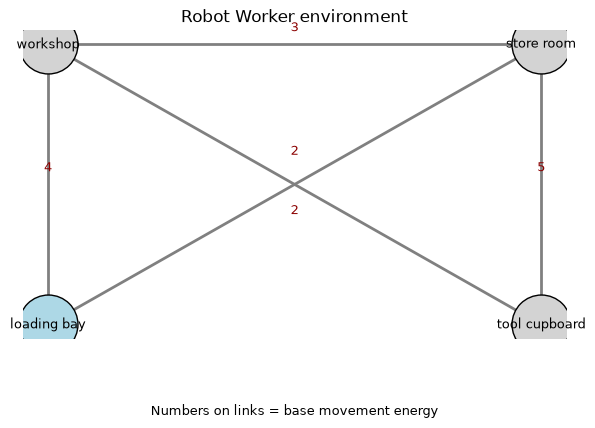

In [11]:
import matplotlib.pyplot as plt


def draw_robot_environment():
    positions = {
        'workshop': (0.0, 1.0),
        'store room': (1.8, 1.0),
        'tool cupboard': (1.8, -0.7),
        'loading bay': (0.0, -0.7),
    }
    links = [
        ('workshop', 'store room'),
        ('store room', 'tool cupboard'),
        ('workshop', 'tool cupboard'),
        ('store room', 'loading bay'),
        ('workshop', 'loading bay'),
    ]

    fig, ax = plt.subplots(figsize=(7, 4))
    for room_a, room_b in links:
        xa, ya = positions[room_a]
        xb, yb = positions[room_b]
        ax.plot([xa, xb], [ya, yb], color='gray', linewidth=2)
        mid_x, mid_y = (xa + xb) / 2, (ya + yb) / 2
        ax.text(mid_x, mid_y + (0.18 if (room_a, room_b) == ('workshop', 'tool cupboard') else -0.18 if (room_a, room_b) == ('store room', 'loading bay') else 0.08), str(TRAVEL_ENERGY_B[frozenset({room_a, room_b})]),
                ha='center', color='darkred', fontsize=9)

    for room, (x, y) in positions.items():
        colour = 'lightblue' if room == 'loading bay' else 'lightgray'
        ax.scatter([x], [y], s=1800, color=colour, edgecolor='black', zorder=3)
        ax.text(x, y, room, ha='center', va='center', fontsize=9, zorder=4)

    ax.text(0.9, -1.25, 'Numbers on links = base movement energy', ha='center', fontsize=9)
    ax.set_axis_off()
    ax.set_title('Robot Worker environment')
    plt.show()


draw_robot_environment()


### Use of Copilot

Insert the actual University-provided Copilot interaction here. Record the suggestions about the scenario, resource constraint, cost function, or heuristic, then explain which suggestions were used, modified, or rejected and why.

Draft placeholder: [Add genuine Copilot evidence and critical evaluation here.]


## B2. Heuristic

The heuristic in `EnergyRobotWorker.heuristic` estimates a lower bound on remaining energy by using the shortest base travel energy to collect one remaining target item and deliver it to the loading bay. If an item is already being carried, it estimates the base energy needed to reach the loading bay. It ignores carrying surcharges and pick-up/put-down costs, so it should not overestimate the real remaining cost and is a deliberately simple admissible heuristic.

The heuristic is intentionally separate from the cost function. The cost function measures energy already consumed, while the heuristic estimates energy still required.


In [12]:
# Basic checks for the heuristic before running search.
print('Base route workshop -> tool cupboard:', shortest_base_energy('workshop', 'tool cupboard'))
print('Base route tool cupboard -> loading bay:', shortest_base_energy('tool cupboard', GOAL_ROOM_B))
print('Initial heuristic:', RW_PROBLEM_B.heuristic(RW_PROBLEM_B.initial_state))


Base route workshop -> tool cupboard: 2
Base route tool cupboard -> loading bay: 6
Initial heuristic: 8


## B3. Experimental Results

The tests below compare uninformed search, search guided by the cost function, search guided by the heuristic, and A*. `return_info=True` keeps the search statistics for the results table. Keep the same node limit, loop checking, and randomisation settings across tests so the comparison is fair.


In [13]:
SEARCH_TESTS_B = [
    {
        'label': 'BFS',
        'search_type': 'BF/FIFO',
        'cost': None,
        'heuristic': None,
    },
    {
        'label': 'DFS',
        'search_type': 'DF/LIFO',
        'cost': None,
        'heuristic': None,
    },
    {
        'label': 'Uniform-cost',
        'search_type': 'BF/FIFO',
        'cost': RW_PROBLEM_B.cost,
        'heuristic': None,
    },
    {
        'label': 'Heuristic-guided',
        'search_type': 'BF/FIFO',
        'cost': None,
        'heuristic': RW_PROBLEM_B.heuristic,
    },
    {
        'label': 'A*',
        'search_type': 'BF/FIFO',
        'cost': RW_PROBLEM_B.cost,
        'heuristic': RW_PROBLEM_B.heuristic,
    },
]

for test in SEARCH_TESTS_B:
    print(test['label'], test['search_type'],
          'cost:', test['cost'] is not None,
          'heuristic:', test['heuristic'] is not None)


BFS BF/FIFO cost: False heuristic: False
DFS DF/LIFO cost: False heuristic: False
Uniform-cost BF/FIFO cost: True heuristic: False
Heuristic-guided BF/FIFO cost: False heuristic: True
A* BF/FIFO cost: True heuristic: True


In [14]:
import pandas as pd


def summarise_search_result(problem, label, raw_result):
    result = raw_result.get('result', {}) if isinstance(raw_result, dict) else {}
    stats = raw_result.get('search_stats', {}) if isinstance(raw_result, dict) else {}
    path = result.get('path')
    goal_state = result.get('goal_state')
    solution_found = result.get('termination_condition') == 'GOAL_STATE_FOUND'
    solution_cost = None
    if solution_found and goal_state is not None:
        solution_cost = problem.cost(path or [], goal_state)
    return {
        'method': label,
        'termination': result.get('termination_condition'),
        'solution_found': solution_found,
        'solution_cost': solution_cost,
        'path_length': len(path) if path else None,
        'nodes_generated': stats.get('nodes_generated'),
        'nodes_left_in_queue': stats.get('nodes_left_in_queue'),
        'time_seconds': stats.get('time_taken'),
    }


def run_part_b_tests(problem=RW_PROBLEM_B, node_limit=100000):
    rows = []
    raw_results = {}
    for test in SEARCH_TESTS_B:
        kwargs = {
            'cost': problem.cost if test['cost'] is not None else None,
            'heuristic': problem.heuristic if test['heuristic'] is not None else None,
            'loop_check': True,
            'randomise': False,
            'show_path': False,
            'show_state_path': False,
            'dots': False,
            'return_info': True,
        }
        raw = search(problem, test['search_type'], node_limit, **kwargs)
        raw_results[test['label']] = raw
        rows.append(summarise_search_result(problem, test['label'], raw))
    return pd.DataFrame(rows), raw_results


results_B, raw_results_B = run_part_b_tests()
results_B


Energy-constrained Robot Worker
Initial battery: 19; goals: {'loading bay': {'anvil', 'screwdriver'}}

** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Search started (progress dot output off)



:-)) *SUCCESS* ((-:

Path length = 7
Goal state is:
Robot location: loading bay
Robot carrying: []
Remaining energy: 0
Room contents: {'workshop': set(), 'store room': set(), 'tool cupboard': {'saw'}, 'loading bay': {'anvil', 'screwdriver'}}

SEARCH SPACE STATS:
Total nodes generated          =     1749  (includes start)
Nodes discarded by loop_check  =      790  (959 distinct states added to queue)
Nodes tested (by goal_test)    =      652  (651 expanded + 1 goal)
Nodes left in queue            =      307

Time taken = 0.2111 seconds

Energy-constrained Robot Worker
Initial battery: 19; goals: {'loading bay': {'anvil', 'screwdriver'}}

** Running Brandon's Search Algorithm **
Strategy: mode=DF/LIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Search started (progress dot output off)



:-)) *SUCCESS* ((-:

Path length = 8
Goal state is:
Robot location: loading bay
Robot carrying: ['saw']
Remaining energy: 0
Room contents: {'workshop': set(), 'store room': set(), 'tool cupboard': set(), 'loading bay': {'anvil', 'screwdriver'}}

SEARCH SPACE STATS:
Total nodes generated          =     1746  (includes start)
Nodes discarded by loop_check  =      914  (832 distinct states added to queue)
Nodes tested (by goal_test)    =      815  (814 expanded + 1 goal)
Nodes left in queue            =       17

Time taken = 0.1858 seconds

Energy-constrained Robot Worker
Initial battery: 19; goals: {'loading bay': {'anvil', 'screwdriver'}}

** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=cost, heuristic=None
Max search nodes: 100000  (max number added to queue)
Search started (progress dot output off)



:-)) *SUCCESS* ((-:

Path length = 7
Goal state is:
Robot location: loading bay
Robot carrying: []
Remaining energy: 1
Room contents: {'workshop': set(), 'store room': set(), 'tool cupboard': {'saw'}, 'loading bay': {'anvil', 'screwdriver'}}
Cost of reaching goal: 18

SEARCH SPACE STATS:
Total nodes generated          =     2736  (includes start)
Nodes discarded by loop_check  =     1458  (1278 distinct states added to queue)
Nodes tested (by goal_test)    =     1020  (1019 expanded + 1 goal)
Nodes left in queue            =      258

Time taken = 0.3124 seconds

Energy-constrained Robot Worker
Initial battery: 19; goals: {'loading bay': {'anvil', 'screwdriver'}}

** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=heuristic
Max search nodes: 100000  (max number added to queue)
Search started (progress dot output off)



:-)) *SUCCESS* ((-:

Path length = 7
Goal state is:
Robot location: loading bay
Robot carrying: []
Remaining energy: 0
Room contents: {'workshop': set(), 'store room': set(), 'tool cupboard': {'saw'}, 'loading bay': {'anvil', 'screwdriver'}}

SEARCH SPACE STATS:
Total nodes generated          =      444  (includes start)
Nodes discarded by loop_check  =      125  (319 distinct states added to queue)
Nodes tested (by goal_test)    =      201  (200 expanded + 1 goal)
Nodes left in queue            =      118

Time taken = 0.0517 seconds

Energy-constrained Robot Worker
Initial battery: 19; goals: {'loading bay': {'anvil', 'screwdriver'}}

** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=cost, heuristic=heuristic
Max search nodes: 100000  (max number added to queue)
Search started (progress dot output off)



:-)) *SUCCESS* ((-:

Path length = 7
Goal state is:
Robot location: loading bay
Robot carrying: []
Remaining energy: 1
Room contents: {'workshop': set(), 'store room': set(), 'tool cupboard': {'saw'}, 'loading bay': {'anvil', 'screwdriver'}}
Cost of reaching goal: 18

SEARCH SPACE STATS:
Total nodes generated          =     1183  (includes start)
Nodes discarded by loop_check  =      406  (777 distinct states added to queue)
Nodes tested (by goal_test)    =      321  (320 expanded + 1 goal)
Nodes left in queue            =      456

Time taken = 0.1591 seconds



,method,termination,solution_found,solution_cost,path_length,nodes_generated,nodes_left_in_queue,time_seconds
0,BFS,GOAL_STATE_FOUND,True,19,7,1749,307,0.211103
1,DFS,GOAL_STATE_FOUND,True,19,8,1746,17,0.185757
2,Uniform-cost,GOAL_STATE_FOUND,True,18,7,2736,258,0.312437
3,Heuristic-guided,GOAL_STATE_FOUND,True,19,7,444,118,0.051740
4,A*,GOAL_STATE_FOUND,True,18,7,1183,456,0.159072


Check the raw results if any statistic appears as `None`: the exact key names can vary between package versions. The report should include solution cost as well as search effort, because the scenario was designed with non-uniform energy costs.


In [15]:
# Save the measured table for later report writing.
results_B.to_csv('part1b_search_results_tested.csv', index=False)
results_B


,method,termination,solution_found,solution_cost,path_length,nodes_generated,nodes_left_in_queue,time_seconds
0,BFS,GOAL_STATE_FOUND,True,19,7,1749,307,0.211103
1,DFS,GOAL_STATE_FOUND,True,19,8,1746,17,0.185757
2,Uniform-cost,GOAL_STATE_FOUND,True,18,7,2736,258,0.312437
3,Heuristic-guided,GOAL_STATE_FOUND,True,19,7,444,118,0.051740
4,A*,GOAL_STATE_FOUND,True,18,7,1183,456,0.159072


## B4. Key Findings

Complete these points only after inspecting the measured table and checking the returned action path:

- [Compare the number of nodes and time for the uninformed and guided searches.]
- [Compare the solution energy cost found by BFS, uniform-cost, heuristic-guided search, and A*.]
- [Explain whether the heuristic reduced search effort and whether it preserved the lowest-cost solution when combined with the cost function.] 
- [Explain how the finite battery affected the available actions or solution choices.] 
- [Discuss any limitations of this scenario and cost model.] 


## Repeatable validation
Run this cell after B3. It replays all five returned paths and checks legal actions, battery, carrying limits, item conservation, and the final goal. Boundary tests verify that 17 energy is insufficient and 18 is sufficient for this scenario. All checks must pass.

In [16]:
from collections import Counter
from contextlib import redirect_stdout
from io import StringIO


def inventory(state):
    return Counter(state.robot.carried_items) + Counter(
        item for contents in state.room_contents.values() for item in contents
    )


initial_snapshot = repr(RW_PROBLEM_B.initial_state)
initial_inventory = inventory(RW_PROBLEM_B.initial_state)
validation_rows_B = []
for method, raw in raw_results_B.items():
    outcome = raw['result']
    assert outcome['termination_condition'] == 'GOAL_STATE_FOUND', method
    state = deepcopy(RW_PROBLEM_B.initial_state)
    energy_sum = 0
    for action in outcome['path']:
        assert action in RW_PROBLEM_B.possible_actions(state), (method, action)
        before = repr(state)
        action_cost = RW_PROBLEM_B.action_energy(state, action)
        next_state = RW_PROBLEM_B.successor(state, action)
        assert repr(state) == before, 'successor mutated its input'
        assert next_state.robot.energy == state.robot.energy - action_cost
        assert next_state.robot.energy >= 0
        assert next_state.robot.weight_carried() <= next_state.robot.strength
        assert inventory(next_state) == initial_inventory
        energy_sum += action_cost
        state = next_state
    assert RW_PROBLEM_B.goal_test(state), method
    assert repr(state) == repr(outcome['goal_state']), method
    assert energy_sum == RW_PROBLEM_B.cost(outcome['path'], state)
    assert RW_PROBLEM_B.heuristic(state) == 0
    validation_rows_B.append({
        'method': method, 'actions': len(outcome['path']),
        'energy_used': energy_sum, 'battery_left': state.robot.energy,
        'path_replay': 'PASS',
    })
assert repr(RW_PROBLEM_B.initial_state) == initial_snapshot
assert RW_PROBLEM_B.initial_state.robot.energy == INITIAL_ENERGY_B

# Independent problem instances prevent a budget test from changing the main scenario.
boundary_rows_B = []
for budget in (17, 18):
    boundary_state = deepcopy(RW_PROBLEM_B.initial_state)
    boundary_state.robot.energy = budget
    boundary_problem = EnergyRobotWorker(boundary_state, deepcopy(goal_item_locations_B))
    with redirect_stdout(StringIO()):
        boundary_raw = search(
            boundary_problem, 'BF/FIFO', 100000, cost=boundary_problem.cost,
            loop_check=True, randomise=False, show_path=False,
            show_state_path=False, dots=False, return_info=True,
        )
    termination = boundary_raw['result']['termination_condition']
    if budget == 17:
        assert termination == 'SEARCH-SPACE_EXHAUSTED', termination
    else:
        assert termination == 'GOAL_STATE_FOUND', termination
        assert boundary_problem.cost(boundary_raw['result']['path'],
                                     boundary_raw['result']['goal_state']) == 18
    boundary_rows_B.append({'initial_energy': budget, 'termination': termination})

validation_B = pd.DataFrame(validation_rows_B)
validation_B.to_csv('part1b_validation_tested.csv', index=False)
print('PASS: all five paths replayed; battery, load, inventory and goal checks passed.')
print('PASS: initial state unchanged; budget 17 impossible, budget 18 sufficient.')
display(validation_B)
display(pd.DataFrame(boundary_rows_B))
print('A* action path:')
for step, action in enumerate(raw_results_B['A*']['result']['path'], 1):
    print(step, action)


PASS: all five paths replayed; battery, load, inventory and goal checks passed.
PASS: initial state unchanged; budget 17 impossible, budget 18 sufficient.


,method,actions,energy_used,battery_left,path_replay
0,BFS,7,19,0,PASS
1,DFS,8,19,0,PASS
2,Uniform-cost,7,18,1,PASS
3,Heuristic-guided,7,19,0,PASS
4,A*,7,18,1,PASS


,initial_energy,termination
0,17,SEARCH-SPACE_EXHAUSTED
1,18,GOAL_STATE_FOUND


A* action path:
1 ('move to', 'tool cupboard')
2 ('pick up', 'anvil')
3 ('pick up', 'screwdriver')
4 ('move to', 'workshop')
5 ('move to', 'loading bay')
6 ('put down', 'anvil')
7 ('put down', 'screwdriver')
